# 01 · Retrieval experiment — which retriever finds the evidence page?
**Mizan AI · AI-4009 Assignment 3** · Usman Bari (23i-0680), Syed Burhan Ahmad (23i-0757)

**Test set:** FinanceBench open sample: 140 test questions over 84 filings, each with a gold evidence page (10 questions are held back as a dev split for prompt writing).
**Alternatives:** `bm25` (keyword baseline) · `bm25:expand` (finance glossary only) · `bm25:route` (company/year routing only) · `bm25x` (both) · `dense` (BGE-small) · `hybrid` (BM25 + dense with RRF) · `hybridx+rerank` (product default, bge-reranker-base)
**Settings:** *scoped* = search inside the question's filing · *open* = search all 84 filings
**Metrics:** Recall@1/3/5/10, MRR@10, nDCG@10 (page level), latency.

> Dense and rerank models download from HuggingFace, so run those on Colab (a GPU is not required but makes it faster). The BM25 rows run anywhere in under a minute.

In [1]:
# --- Setup (works on Google Colab and locally) ---------------------------------
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists("mizan-ai"):
    subprocess.run(["git", "clone", "https://github.com/usmanbari-ub/mizan-ai.git"], check=True)
ROOT = os.path.abspath("mizan-ai" if IN_COLAB else "../..")
os.chdir(os.path.join(ROOT, "eval"))
sys.path[:0] = [os.path.join(ROOT, "eval"), os.path.join(ROOT, "backend")]
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", os.path.join(ROOT, "backend/requirements.txt")], check=True)
print("working dir:", os.getcwd())

working dir: C:\Users\usmanbari\Downloads\mizan-ai (1)\mizan-ai\eval


In [2]:
# FinanceBench PDFs (~160 MB, from github.com/patronus-ai/financebench)
from common import financebench_pdf_dir
try:
    print(financebench_pdf_dir())
except FileNotFoundError:
    subprocess.run([sys.executable, "download_financebench.py"], check=True)

C:\Users\usmanbari\Downloads\mizan-ai (1)\mizan-ai\eval\data\financebench_pdfs


In [3]:
from run_retrieval import run
# Lexical retrievers + ablations (no models needed)
res_lex = run(["bm25", "bm25:expand", "bm25:route", "bm25x"], ["scoped", "open"])

store: 84 filings, 36473 chunks
[bm25] ready in 0s


  scoped R@1=0.154 R@5=0.363 R@10=0.449 MRR=0.249 p50=33.7ms


  open   R@1=0.071 R@5=0.124 R@10=0.163 MRR=0.096 p50=272.2ms
[bm25:expand] ready in 0s


  scoped R@1=0.193 R@5=0.509 R@10=0.670 MRR=0.358 p50=43.0ms


  open   R@1=0.050 R@5=0.135 R@10=0.181 MRR=0.084 p50=405.6ms


[bm25:route] ready in 0s


  scoped R@1=0.154 R@5=0.363 R@10=0.449 MRR=0.249 p50=38.6ms


  open   R@1=0.111 R@5=0.284 R@10=0.363 MRR=0.192 p50=6.9ms


[bm25x] ready in 0s


  scoped R@1=0.193 R@5=0.509 R@10=0.670 MRR=0.358 p50=47.1ms


  open   R@1=0.146 R@5=0.409 R@10=0.542 MRR=0.281 p50=10.2ms


In [4]:
print("Dense / hybrid / rerank: run separately on a GPU by Burhan (see summary.json).")


Dense / hybrid / rerank: run separately on a GPU by Burhan (see summary.json).


In [5]:
import json, pandas as pd
summary = json.load(open("results/summary.json"))["retrieval"]
df = pd.DataFrame(summary).T[["recall@1","recall@3","recall@5","recall@10","mrr@10","ndcg@10","latency_p50_ms","failures_at5"]]
df.index.name = "retriever|setting"
df

,recall@1,recall@3,recall@5,recall@10,mrr@10,ndcg@10,latency_p50_ms,failures_at5
retriever|setting,,,,,,,,
bm25|scoped,0.1536,0.2952,0.3631,0.4488,0.2487,0.2919,33.7,86
bm25|open,0.0714,0.1071,0.1238,0.1631,0.0956,0.1108,272.2,122
bm25:expand|scoped,0.1929,0.4202,0.5095,0.6702,0.3576,0.4218,43.0,62
bm25:expand|open,0.05,0.0893,0.1345,0.181,0.0836,0.1054,405.6,120
bm25:route|scoped,0.1536,0.2952,0.3631,0.4488,0.2487,0.2919,38.6,86
bm25:route|open,0.1107,0.2238,0.2845,0.3631,0.1916,0.2281,6.9,97
bm25x|scoped,0.1929,0.4202,0.5095,0.6702,0.3576,0.4218,47.1,62
bm25x|open,0.1464,0.3095,0.4095,0.5417,0.2805,0.3343,10.2,76


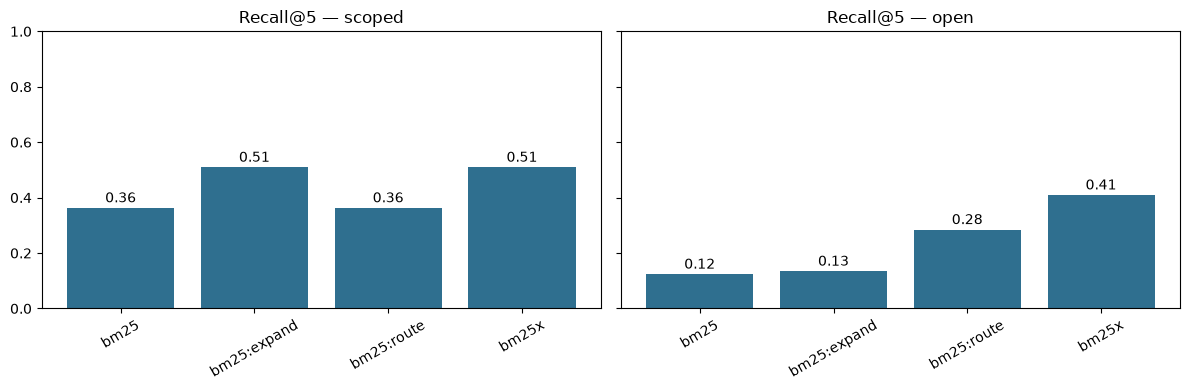

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, setting in zip(axes, ["scoped", "open"]):
    sub = df[[i.endswith("|" + setting) for i in df.index]]
    ax.bar([i.split("|")[0] for i in sub.index], sub["recall@5"].astype(float), color="#2f6f8f")
    ax.set_title(f"Recall@5 — {setting}"); ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=30)
    for x, v in enumerate(sub["recall@5"].astype(float)): ax.text(x, v + .02, f"{v:.2f}", ha="center")
plt.tight_layout(); os.makedirs("results/figures", exist_ok=True); plt.savefig("results/figures/retrieval_recall5.png", dpi=150); plt.show()

## Error analysis (≥ 10 failures grouped by cause)
Failures = gold page not in the top 5. Causes are tagged automatically, then checked by hand:
* **vocabulary_mismatch**: the question uses analyst words (capex, quick ratio) and the filing uses statement words (purchases of PP&E). *Fix:* glossary expansion (done → `bm25x`), dense embeddings.
* **wrong_company / wrong_period_same_company** (open setting): the right company but the wrong year's filing. *Fix:* company/year metadata routing (done).
* **adjacent_page**: the statement continues on the next page. *Fix:* return page ±1 as context, or merge continued statements.
* **short_or_vague_question**: e.g. "Is 3M capital-intensive?" needs several pages. *Fix:* the agent runs multiple searches (agent mode).

In [7]:
best = "bm25x"
fails = json.load(open(f"results/retrieval_failures_{best}_scoped.json"))
print(len(fails), "failures for", best, "(scoped)")
fdf = pd.DataFrame([{"cause": f["cause"], "type": f["type"], "gold_pages": [p for _, p in f["gold"]],
                     "top5_pages": [p for _, p in f["top5"]], "question": f["question"][:110]} for f in fails])
display(fdf.groupby("cause").size().rename("count").to_frame())
fdf.groupby("cause").head(4).sort_values("cause")

62 failures for bm25x (scoped)


,count
cause,
adjacent_page,10
short_or_vague_question,17
vocabulary_mismatch,35


,cause,type,gold_pages,top5_pages,question
0,adjacent_page,domain-relevant,"[48, 50, 52]","[37, 61, 47, 15, 62]",Is 3M a capital-intensive business based on FY...
8,adjacent_page,metrics-generated,[38],"[49, 26, 25, 53, 39]",What is Amazon's year-over-year change in reve...
22,adjacent_page,metrics-generated,[86],"[106, 39, 68, 87, 65]",How much (in USD billions) did American Water ...
26,adjacent_page,metrics-generated,[52],"[64, 49, 53, 85, 41]",We need to calculate a financial metric by usi...
1,short_or_vague_question,novel-generated,[25],"[28, 121, 31, 32, 19]","If we exclude the impact of M&A, which segment..."
6,short_or_vague_question,novel-generated,[57],"[6, 10, 5, 24, 12]",Does Adobe have an improving Free cashflow con...
12,short_or_vague_question,domain-relevant,[5],"[14, 7, 46, 15, 12]",What industry does AMCOR primarily operate in?
14,short_or_vague_question,domain-relevant,[4],"[7, 60, 69, 111, 38]",What are the major products and services that ...
2,vocabulary_mismatch,domain-relevant,[1],"[27, 19, 73, 70, 5]",Which debt securities are registered to trade ...
3,vocabulary_mismatch,metrics-generated,"[69, 70]","[86, 66, 30, 55, 94]",What is the FY2019 fixed asset turnover ratio ...


**Note on test-set hygiene:** the finance glossary in `backend/mizan/retrieval/query.py` was written after looking at 8 BM25 failures from this test split, so the `bm25:expand` gain on FinanceBench may be slightly optimistic. We therefore re-check it on the unseen PSX test set (notebook 03), which was not looked at while writing the glossary.